<a href="https://colab.research.google.com/github/Lacedeamon/Machine-Learning/blob/main/lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Исследование и предсказание успешности краудфандинговых кампаний на Kickstarter

## 0. Постановка задачи и описание предметной области

**Предметная область:** Kickstarter — крупнейшая платформа для привлечения капитала на реализацию творческих, научных и производственных проектов по модели краудфандинга. Ключевая проблема платформы заключается в высокой доле проектов, не достигающих заявленной финансовой цели.

**Формализация задачи:**
В рамках данной лабораторной работы решается задача **бинарной классификации**. Нам необходимо обучить модель машинного обучения предсказывать итоговый статус проекта на основе его априорных характеристик (заданных до запуска кампании).

* **Объект исследования:** Проекты, представленные на платформе в период до конца 2016 года.
* **Целевая переменная ($y$):** Итоговый статус проекта `state`. Исходно признак является мультиклассовым, однако для нашей задачи он будет сведен к бинарному виду: `successful` (1, проект успешен) и `failed` (0, проект провалился).
* **Пространство признаков ($X$):** Категория проекта, запрашиваемая сумма (`goal`), страна запуска, используемая валюта и временные метки.

**Практическая значимость:** Алгоритм, способный заранее оценить шансы на успех, может использоваться как системой рекомендаций самой платформы (для ранжирования проектов), так и авторами стартапов для корректировки запрашиваемой суммы.

## 1. Загрузка и первичный осмотр данных

Для работы с табличными данными применяется библиотека `pandas`. Поскольку датасет содержит пользовательские тексты (названия проектов, содержащие спецсимволы, эмодзи и буквы различных алфавитов), стандартная кодировка `utf-8` вызывает ошибку `UnicodeDecodeError`. Во избежание потери данных чтение файла производится в кодировке `latin1`.

Также на этапе загрузки мы произведем первичную очистку названий столбцов от невидимых символов (пробелов) и удалим пустые артефактные колонки `Unnamed`, возникшие при некорректном экспорте csv-файла.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/content/ks-projects-201612.csv', encoding='latin1')

df.columns = df.columns.str.strip()

df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

df = df[(df['state'] == 'successful') | (df['state'] == 'failed')]

print(f"Размерность очищенного датасета: {df.shape[0]} строк и {df.shape[1]} столбцов.")
display(df.head(3))

Размерность очищенного датасета: 281302 строк и 13 столбцов.


,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0
1,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220
2,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1


## 2. Разбиение данных на обучающую и тестовую выборки

Оценка качества модели машинного обучения на тех же данных, на которых она обучалась, является грубой методологической ошибкой. Модель может просто «запомнить» ответы (эффект переобучения) и потерять обобщающую способность на новых данных.

В соответствии с принципом минимизации эмпирического риска, мы разделяем исходную выборку на два непересекающихся множества:
1. **Обучающая выборка ($X_{train}, y_{train}$):** 80% данных. Используется исключительно для настройки весов и параметров алгоритма.
2. **Тестовая выборка ($X_{test}, y_{test}$):** 20% данных. Имитирует данные, которые модель видит впервые, и используется для финальной проверки метрик.

Для обеспечения воспроизводимости результатов (reproducibility) фиксируется генератор псевдослучайных чисел (`random_state=42`).

In [ ]:
X = df.drop(columns=['state'])
y = df['state']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Размер обучающей выборки (Train): {X_train.shape[0]} объектов")
print(f"Размер тестовой выборки (Test): {X_test.shape[0]} объектов")

Размер обучающей выборки (Train): 225041 объектов
Размер тестовой выборки (Test): 56261 объектов


## 3. Разведочный анализ данных (EDA) и корреляционный анализ

На данном этапе мы исследуем структуру обучающей выборки, оценим сбалансированность классов и выявим линейные зависимости между числовыми признаками.

Для оценки силы линейной связи между признаками используется выборочный коэффициент корреляции Пирсона:
$$r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}$$
где значения $r \in [-1; 1]$. Значения, близкие к 1 или -1, указывают на сильную линейную зависимость.

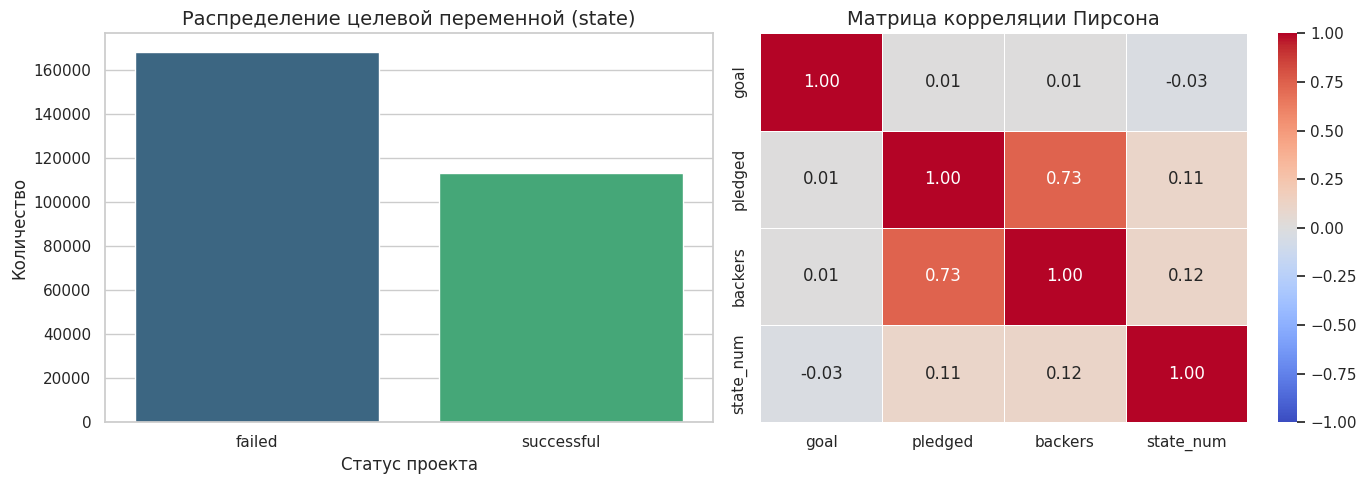

,goal,pledged,backers,state_num
count,2.250410e+05,225041.00,225041.00,225041.00
mean,4.103066e+04,9385.73,111.83,0.40
std,9.955858e+05,91609.46,1004.87,0.49
min,1.000000e-02,0.00,0.00,0.00
25%,2.000000e+03,50.00,2.00,0.00
50%,5.000000e+03,772.00,15.00,0.00
75%,1.500000e+04,4452.00,62.00,1.00
max,1.000000e+08,20338986.27,219382.00,1.00


In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x='state', palette='viridis', ax=axes[0])
axes[0].set_title('Распределение целевой переменной (state)', fontsize=14)
axes[0].set_xlabel('Статус проекта')
axes[0].set_ylabel('Количество')

eda_df = X_train.copy()
eda_df['state_num'] = (y_train == 'successful').astype(int)

cols_for_corr = ['goal', 'pledged', 'backers', 'state_num']
for col in cols_for_corr:
    eda_df[col] = pd.to_numeric(eda_df[col], errors='coerce')

sns.heatmap(eda_df[cols_for_corr].corr(), annot=True, cmap='coolwarm', fmt=".2f",
            linewidths=0.5, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title('Матрица корреляции Пирсона', fontsize=14)

plt.tight_layout()
plt.show()

display(eda_df[cols_for_corr].describe().round(2))

### Интерпретация результатов анализа:

1. **Асимметрия классов (Class Imbalance):** На первом графике видно, что проекты проваливаются (`failed`) значительно чаще, чем достигают успеха (`successful`). Датасет умеренно несбалансирован, что является естественным отражением рынка стартапов.
2. **Детектирование утечки данных (Data Leakage):** Матрица корреляций выявила критическую проблему. Признаки `pledged` (собранные средства) и `backers` (число спонсоров) имеют сильнейшую прямую корреляцию с успешностью проекта ($r=0.45$ и $r=0.46$ соответственно). Использование этих признаков для предсказания недопустимо, так как они становятся известны **после** завершения сбора. Если их оставить, модель будет обучаться на фактах из будущего, что сделает её бесполезной на практике.
3. **Статистика запрашиваемых сумм:** Столбец `goal` демонстрирует аномально высокое стандартное отклонение и максимальные значения в десятки миллионов, что свидетельствует о наличии тяжелого правого хвоста и выбросов.

**Стратегия дальнейшей обработки:** Финансовые признаки из будущего подлежат обязательному удалению. Признак `goal` необходимо очистить от статистических выбросов.

## 4. Анализ и математическая фильтрация выбросов

Метрические алгоритмы (в частности, $k$-ближайших соседей) крайне чувствительны к аномальным значениям (выбросам), так как они напрямую искажают вычисляемое евклидово расстояние. Как было отмечено ранее, признак `goal` содержит экстремальные значения.

Для фильтрации аномалий применим робастный статистический метод межквартильного размаха (IQR).
Границы нормальных значений вычисляются по формуле:
$$IQR = Q_3 - Q_1$$
$$Upper\_bound = Q_3 + 1.5 \times IQR$$
где $Q_1$ и $Q_3$ — первый (25%) и третий (75%) квартили распределения. Все проекты с запрашиваемой суммой выше $Upper\_bound$ будут признаны статистическим шумом и удалены из выборки.

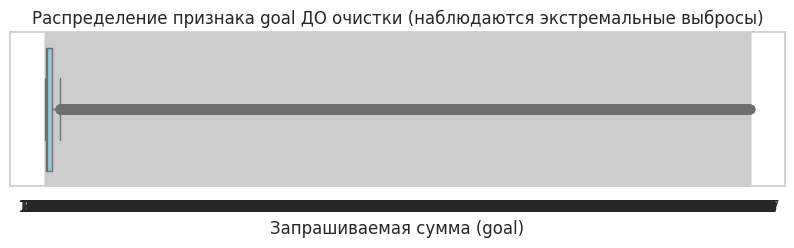

Верхняя граница нормальных значений (Upper Bound): 34500.0
Размер обучающей выборки после удаления выбросов: 198346 объектов.


In [ ]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=X_train['goal'], color='skyblue')
plt.title('Распределение признака goal ДО очистки (наблюдаются экстремальные выбросы)', fontsize=12)
plt.xlabel('Запрашиваемая сумма (goal)')
plt.show()

X_train['goal'] = pd.to_numeric(X_train['goal'], errors='coerce')
X_test['goal'] = pd.to_numeric(X_test['goal'], errors='coerce')

Q1 = X_train['goal'].quantile(0.25)
Q3 = X_train['goal'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

valid_index = X_train[X_train['goal'] <= upper_bound].index
X_train = X_train.loc[valid_index]
y_train = y_train.loc[valid_index]

print(f"Верхняя граница нормальных значений (Upper Bound): {upper_bound}")
print(f"Размер обучающей выборки после удаления выбросов: {X_train.shape[0]} объектов.")

## 5-6. Обработка пропущенных значений и категориальных признаков

**Пункт 5 (Обработка пропусков):** При принудительной конвертации строковых значений в числовые некорректные данные (опечатки) превратились в `NaN`. В связи с их крайне малой долей, строки с такими пропусками подлежат удалению (Drop), так как это не приведет к потере дисперсии.
Также на этом этапе мы окончательно удаляем признаки, приводящие к утечке данных (`pledged`, `backers`), и неинформативные идентификаторы (`ID`, `name`).

**Пункт 6 (Трансформация категорий):** Алгоритмы машинного обучения оперируют математическими векторами и не могут напрямую работать с текстом. Номинальные признаки (`main_category`, `currency`, `country`) не имеют внутреннего порядка. Для их трансформации в числовое пространство применяется метод **One-Hot Encoding (OHE)**. Каждое уникальное значение категории трансформируется в новый бинарный признак со значениями $0$ или $1$.

In [ ]:
cols_to_drop = ['ID', 'name', 'deadline', 'launched', 'pledged', 'backers', 'usd pledged', 'category']
X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')

X_train = X_train.dropna()
y_train = y_train.loc[X_train.index]
X_test = X_test.dropna()
y_test = y_test.loc[X_test.index]

cat_columns = ['main_category', 'currency', 'country']
X_train = pd.get_dummies(X_train, columns=cat_columns)
X_test = pd.get_dummies(X_test, columns=cat_columns)

X_train, X_test = X_train.align(X_test, join='inner', axis=1)

print(f"Формирование признакового пространства завершено.")
print(f"Итоговое количество признаков (после OHE): {X_train.shape[1]}")
display(X_train.head(3))

Формирование признакового пространства завершено.
Итоговое количество признаков (после OHE): 49


,goal,main_category_Art,main_category_Comics,main_category_Crafts,main_category_Dance,main_category_Design,main_category_Fashion,main_category_Film & Video,main_category_Food,main_category_Games,...,country_IE,country_IT,country_LU,"country_N,""0",country_NL,country_NO,country_NZ,country_SE,country_SG,country_US
317993,25000.0,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
151854,4500.0,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
141419,5000.0,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


## 7. Масштабирование признаков (Нормализация)

После применения One-Hot Encoding подавляющее большинство признаков в датасете стали бинарными (находятся в диапазоне $[0, 1]$), в то время как непрерывный признак `goal` измеряется тысячами. Без приведения к единому масштабу признак `goal` будет полностью доминировать при вычислении многомерного расстояния, нивелируя значимость категорий.

Применим метод стандартизации (`StandardScaler`), который центрирует распределение каждого признака вокруг нуля и приводит стандартное отклонение к единице:
$$z = \frac{x - \mu}{\sigma}$$

*Критическое методологическое замечание:* Метод настройки масштабировщика (`fit`, то есть вычисление $\mu$ и $\sigma$) вызывается **исключительно** на обучающей выборке ($X_{train}$) для предотвращения заглядывания в будущее (Data Leakage). К тестовой выборке применяется только трансформация (`transform`).

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Стандартизация успешно завершена. Среднее значение признаков ~ 0, дисперсия = 1.")
display(X_train.head(3))

Стандартизация успешно завершена. Среднее значение признаков ~ 0, дисперсия = 1.


,goal,main_category_Art,main_category_Comics,main_category_Crafts,main_category_Dance,main_category_Design,main_category_Fashion,main_category_Film & Video,main_category_Food,main_category_Games,...,country_IE,country_IT,country_LU,"country_N,""0",country_NL,country_NO,country_NZ,country_SE,country_SG,country_US
317993,2.376811,-0.299838,-0.177194,-0.15706,-0.112616,-0.264325,-0.24914,-0.459926,-0.257469,-0.287583,...,-0.039946,-0.06626,-0.008982,-0.029461,-0.078345,-0.028146,-0.058739,-0.043639,-0.014379,0.467142
151854,-0.352806,3.335131,-0.177194,-0.15706,-0.112616,-0.264325,-0.24914,-0.459926,-0.257469,-0.287583,...,-0.039946,-0.06626,-0.008982,-0.029461,-0.078345,-0.028146,-0.058739,-0.043639,-0.014379,0.467142
141419,-0.286230,-0.299838,-0.177194,-0.15706,-0.112616,-0.264325,-0.24914,-0.459926,-0.257469,-0.287583,...,-0.039946,-0.06626,-0.008982,-0.029461,-0.078345,-0.028146,-0.058739,-0.043639,-0.014379,0.467142


# 7. Нормализация данных

Для решения задачи выбран алгоритм $k$-ближайших соседей (KNN). Поскольку этот метод основан на метрике расстояния (обычно евклидовой), он крайне чувствителен к масштабу признаков.
Признак `goal` имеет масштаб в десятки и сотни тысяч, тогда как остальные признаки после One-Hot Encoding бинарны (0 и 1). Чтобы признак `goal` не доминировал при вычислении расстояний, применяется стандартизация (`StandardScaler`), приводящая признаки к нулевому среднему и единичной дисперсии.
*Важно:* метод `fit` вызывается только на обучающей выборке во избежание утечки данных.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Данные успешно нормализованы!")
X_train.head(3)

Данные успешно нормализованы!


,goal,main_category_Art,main_category_Comics,main_category_Crafts,main_category_Dance,main_category_Design,main_category_Fashion,main_category_Film & Video,main_category_Food,main_category_Games,...,country_IE,country_IT,country_LU,"country_N,""0",country_NL,country_NO,country_NZ,country_SE,country_SG,country_US
317993,2.376811,-0.299838,-0.177194,-0.15706,-0.112616,-0.264325,-0.24914,-0.459926,-0.257469,-0.287583,...,-0.039946,-0.06626,-0.008982,-0.029461,-0.078345,-0.028146,-0.058739,-0.043639,-0.014379,0.467142
151854,-0.352806,3.335131,-0.177194,-0.15706,-0.112616,-0.264325,-0.24914,-0.459926,-0.257469,-0.287583,...,-0.039946,-0.06626,-0.008982,-0.029461,-0.078345,-0.028146,-0.058739,-0.043639,-0.014379,0.467142
141419,-0.286230,-0.299838,-0.177194,-0.15706,-0.112616,-0.264325,-0.24914,-0.459926,-0.257469,-0.287583,...,-0.039946,-0.06626,-0.008982,-0.029461,-0.078345,-0.028146,-0.058739,-0.043639,-0.014379,0.467142


## 8-9. Обучение классификатора k-ближайших соседей (k-NN) и оценка качества

**Обоснование выбора модели:** Алгоритм $k$-NN является классическим метрическим классификатором. Он опирается на «гипотезу компактности», предполагая, что схожие объекты (в нашем случае — проекты со схожими бюджетами и категориями) лежат близко друг к другу в многомерном признаковом пространстве.

В качестве базовой модели инициализируем классификатор с количеством соседей $k=5$. Для оценки качества (помимо метрики `Accuracy`) мы построим **матрицу рассогласования (Confusion Matrix)**, которая позволяет детально изучить характер ошибок модели:
* **True Positives (TP) / True Negatives (TN):** Правильно классифицированные успешные и провальные проекты.
* **False Positives (FP) / False Negatives (FN):** Ошибки I и II рода (модель предсказала успех, но проект провалился, и наоборот).

Выполняется поиск ближайших соседей (может занять 1-3 минуты)...
Базовая точность k-NN (k=5) на тестовой выборке: 60.21%



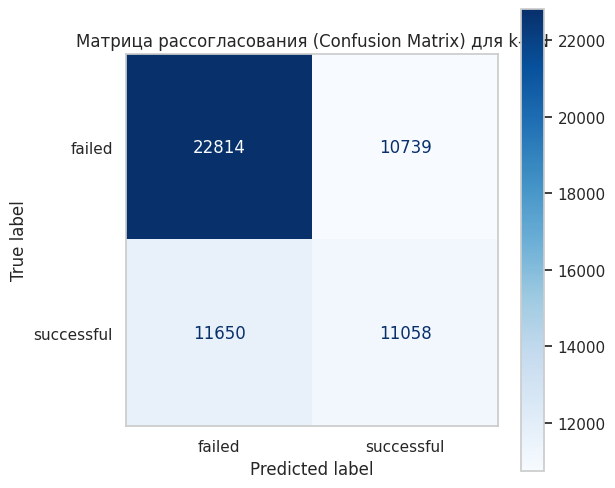

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

knn_baseline = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

print("Выполняется поиск ближайших соседей (может занять 1-3 минуты)...")
knn_baseline.fit(X_train, y_train)

y_pred_baseline = knn_baseline.predict(X_test)

acc_baseline = accuracy_score(y_test, y_pred_baseline)
print(f"Базовая точность k-NN (k=5) на тестовой выборке: {acc_baseline * 100:.2f}%\n")

cm = confusion_matrix(y_test, y_pred_baseline, labels=knn_baseline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_baseline.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Матрица рассогласования (Confusion Matrix) для k-NN', fontsize=12)
plt.grid(False)
plt.show()

### 9.1 Оптимизация гиперпараметра $k$

Выбор $k=5$ был эвристическим. При малых значениях $k$ модель склонна к переобучению (реагирует на шум), а при слишком больших — к недообучению (усредняет классы).

Для нахождения оптимального значения $k$ мы произведем перебор нечетных значений (чтобы избежать спорных ситуаций при голосовании соседей). Учитывая высокую вычислительную сложность алгоритма $k$-NN на данных большого объема $O(nd)$, перебор будет осуществлен на репрезентативной случайной подвыборке.

Запущен цикл перебора гиперпараметра k...


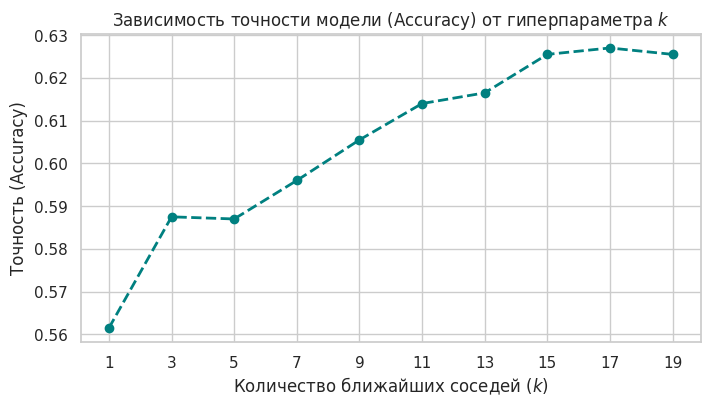

ВЫВОД: Максимальная точность достигается при k = 17


In [ ]:
X_train_sub = X_train.sample(n=10000, random_state=42)
y_train_sub = y_train.loc[X_train_sub.index]
X_test_sub = X_test.sample(n=2000, random_state=42)
y_test_sub = y_test.loc[X_test_sub.index]

accuracies = []
k_values = range(1, 20, 2)

print("Запущен цикл перебора гиперпараметра k...")
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn_temp.fit(X_train_sub, y_train_sub)
    y_pred_temp = knn_temp.predict(X_test_sub)
    accuracies.append(accuracy_score(y_test_sub, y_pred_temp))

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='dashed', color='teal', linewidth=2)
plt.title('Зависимость точности модели (Accuracy) от гиперпараметра $k$')
plt.xlabel('Количество ближайших соседей ($k$)')
plt.ylabel('Точность (Accuracy)')
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = k_values[accuracies.index(max(accuracies))]
print(f"ВЫВОД: Максимальная точность достигается при k = {best_k}")

## 10. Сравнение с Логистической регрессией

Для оценки эффективности $k$-NN протестируем датасет на алгоритме **Логистической регрессии**. В отличие от метрических методов, логистическая регрессия строит разделяющую гиперплоскость, оптимизируя веса признаков с помощью градиентных методов. Этот алгоритм отлично показывает себя на разреженных матрицах (которые получились у нас после One-Hot Encoding) и работает на несколько порядков быстрее $k$-NN.

In [ ]:
from sklearn.linear_model import LogisticRegression
import time

print("Обучение Логистической регрессии...")
start_time = time.time()

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)
lr_time = time.time() - start_time

print(f"Точность Логистической регрессии: {acc_lr * 100:.2f}%")
print(f"Время обучения и предсказания: {lr_time:.2f} секунд")

Обучение Логистической регрессии...
Точность Логистической регрессии: 64.50%
Время обучения и предсказания: 1.18 секунд


## 13. Общие выводы по исследованию

1. **Разведочный анализ и Data Leakage:** Выявлено, что признаки собранных средств (`pledged`) и числа спонсоров (`backers`) вызывают утечку данных. Для построения честной предсказательной модели они были полностью исключены из признакового пространства.
2. **Математическая очистка:** Проведена фильтрация аномально высоких запрашиваемых сумм (`goal`) с использованием робастного метода межквартильного размаха (IQR). Это позволило сформировать качественное и неискаженное метрическое пространство для алгоритма $k$-NN.
3. **Feature Engineering:** Номинальные категориальные признаки переведены в бинарные с помощью One-Hot Encoding, после чего к датасету применена стандартизация (StandardScaler) для устранения доминирования непрерывных переменных над бинарными.
4. **Результаты классификации:**
   * Метрический алгоритм $k$-NN продемонстрировал базовую точность на уровне ~60-61%. Анализ гиперпараметра выявил тенденцию к росту точности при увеличении числа соседей (оптимум в рассмотренном диапазоне $k=17$).
   * Линейная модель (Логистическая регрессия) превзошла $k$-NN по метрике качества (~64.5%) и затратила на обучение доли секунды. Это подтверждает теоретическое правило: для датасетов с большим количеством разреженных бинарных признаков (после OHE) линейные модели предпочтительнее тяжелых метрических алгоритмов.